# 一只狗怎么站起来？控制和学习各管什么

配套《手推到狗跑》视频。Lite3 机器狗站在一块会晃的板子上（MuJoCo 仿真），对比四种做法：

| 做法 | 上层（每条腿多长） | 底层 |
|---|---|---|
| 关掉电机 | 无 | 无 |
| 只有关节 PD | 固定站姿 | 关节 PD |
| 手推平衡层 | 腿长几何 h = 2L·cosθ 推出来 | 关节 PD |
| 学出来的平衡层 | 4 个数，从试错的回报里学 | 关节 PD |

从上往下依次运行每一格。全部跑完大约 10 分钟（学习那两格最慢）。

## 检查环境（先运行这一格）

报 `No module named ...` 时运行这一格就行：它会把缺的包装进你当前选中的内核。

In [ ]:
# 第一次运行：检查需要的包，缺哪个就装进当前这个内核（已经装过的直接跳过）
import importlib.util
need = [p for p in ['numpy', 'matplotlib', 'mujoco'] if importlib.util.find_spec(p) is None]
if need:
    get_ipython().run_line_magic('pip', 'install ' + ' '.join(need))
    need = [p for p in need if importlib.util.find_spec(p) is None]
print('环境就绪' if not need else '还缺：' + ', '.join(need) + '（看上面 pip 的报错，或换一个 Python 内核）')


## 仿真代码（先运行这一格）

和同文件夹的 `balance_sim.py` 内容相同，放在这里是为了让 notebook 单独也能运行（模型文件需要放在同目录的 `lite3/` 里）。不用读懂它，知道 `simulate(Case(...))` 会返回机身倾角等时间序列、`train(...)` 会学出平衡层的 4 个参数就够了。

In [1]:
"""一只狗怎么站起来：Lite3 站在会倾斜的板子上，对比四种“控制器”。

    off      关掉电机：力矩为 0
    pd       只有关节 PD：把 12 个关节锁在站姿（底层，500 Hz）
    geom     PD + 手推平衡层：用腿长几何 h = 2L·cosθ 把“板子歪了多少”算出来，调左右/前后腿长（上层，50 Hz）
    learned  PD + 学出来的平衡层：同一个接口，参数用随机搜索（ARS 思路）从仿真回报里学

两层结构：上层（平衡层）只决定“每条腿多长”，底层关节 PD 负责“跟上”。
模型：DeepRoboticsLab/deep_robotics_model 的 Lite3 MJCF（BSD-3-Clause）。参数为教学设置，不代表实机。
运行环境：pip install mujoco（测试版本 3.16）。直接运行本文件 = 跑四种情况并打印指标。
"""
from dataclasses import dataclass, field
from pathlib import Path

import mujoco
import numpy as np

try:
    _HERE = Path(__file__).resolve().parent
except NameError:                  # 在 notebook 格子里运行时没有 __file__
    _HERE = Path.cwd()
# 发布包里模型放在同文件夹的 lite3/；找不到时退回作者本地的模型路径
MJCF = next((p for p in [_HERE / "lite3", _HERE.parents[1] / "assets" / "deep_robotics_model-main" / "Lite3" / "mjcf"]
             if (p / "Lite3.xml").exists()), _HERE / "lite3")

# ---------------- 模型 ----------------
L = 0.2051                 # 大腿 = 小腿长度（m），由站姿正运动学反推：0.286 = 2L·cos0.8
H0 = 2 * L * np.cos(0.8)   # 站立腿长 ≈ 0.286 m（髋到足心）
H_MIN, H_MAX = 0.20, 0.37
W = 0.318                  # 左右足距（m）
LX = 0.349                 # 前后足距（m）
LEG_Y = np.array([1, -1, 1, -1])   # FL FR HL HR：左 +1 / 右 -1
LEG_X = np.array([1, 1, -1, -1])   # 前 +1 / 后 -1
DT = 0.002                 # 物理与关节 PD 步长 2 ms（500 Hz）
BAL_EVERY = 10             # 平衡层每 10 步更新一次（50 Hz）
KP, KD, TAU_MAX = 60.0, 1.5, 30.0   # KP=40 时机身有约 1 Hz 的前后晃动，上层一叠加就失控（见翻车记录）
BOARD_Z = 0.30             # 板子转轴高度


LITE3_FILES = ["Lite3.xml", "LICENSE.txt"] + [f"meshes/{n}.STL" for n in ("torso", "hip", "thigh", "shank")]
LITE3_URLS = ["https://gitee.com/nononodoubt/shoutui-daogoupao/raw/main/四足/一只狗怎么站起来/lite3/",
              "https://fastly.jsdelivr.net/gh/NONONODOUBT/shoutui-daogoupao@main/四足/一只狗怎么站起来/lite3/",
              "https://raw.githubusercontent.com/NONONODOUBT/shoutui-daogoupao/main/四足/一只狗怎么站起来/lite3/"]


def download_lite3(dst):
    """只拿到 notebook、旁边没有 lite3/ 时，从配套仓库下载模型（约 3 MB，国内先走 Gitee）。"""
    from urllib.parse import quote
    from urllib.request import urlopen
    for base in LITE3_URLS:
        try:
            for f in LITE3_FILES:
                data = urlopen(quote(base + f, safe=":/@"), timeout=30).read()
                (dst / f).parent.mkdir(parents=True, exist_ok=True)
                (dst / f).write_bytes(data)
            print(f"已下载 Lite3 模型到 {dst}")
            return
        except OSError as e:
            print(f"从 {base.split('/')[2]} 下载失败（{e}），换一个地址")
    raise FileNotFoundError(f"找不到 Lite3 模型：请把配套仓库里的 lite3/ 文件夹放到 {dst.parent}")


def load_model():
    """MuJoCo 在 Windows 上打不开中文路径：自己读 XML 和网格，以内容形式传进去。"""
    if not (MJCF / "Lite3.xml").exists():
        download_lite3(MJCF)
    xml = (MJCF / "Lite3.xml").read_text(encoding="utf-8")
    assets = {f"./meshes/{p.name}": p.read_bytes() for p in (MJCF / "meshes").iterdir()}
    spec = mujoco.MjSpec.from_string(xml, assets)
    spec.assets = {k[2:]: v for k, v in assets.items()}     # compile 时按 meshes/xxx 查找
    # 画面：渐变天空（和讲解画布同色系）、淡一点的地面格子
    spec.add_texture(name="sky", type=mujoco.mjtTexture.mjTEXTURE_SKYBOX, builtin=mujoco.mjtBuiltin.mjBUILTIN_GRADIENT,
                     rgb1=[0.62, 0.76, 0.92], rgb2=[0.09, 0.13, 0.23], width=512, height=3072)
    for t in spec.textures:
        if t.name == "checker":
            t.rgb1, t.rgb2 = [0.70, 0.75, 0.82], [0.86, 0.89, 0.93]
    board = spec.worldbody.add_body(name="board", pos=[0, 0, BOARD_Z], mocap=True)
    board.add_geom(type=mujoco.mjtGeom.mjGEOM_BOX, size=[0.6, 0.45, 0.02], pos=[0, 0, -0.02],
                   rgba=[0.85, 0.62, 0.38, 1], friction=[1.0, 0.01, 0.01])
    m = spec.compile()
    m.opt.timestep = DT
    m.vis.global_.offwidth, m.vis.global_.offheight = 1920, 1080     # 离屏渲染用 1080p
    dog = m.geom_bodyid > 0
    vis = dog & (m.geom_group == 2) & (m.geom_matid < 0)                 # 机身改成中性灰，和蓝天分得开
    m.geom_rgba[vis] = [0.58, 0.60, 0.64, 1]
    return m


def leg_angles(h):
    """腿长 → 关节角（足在髋正下方）：h = 2L·cosθ，髋 = -θ，膝 = 2θ。"""
    th = np.arccos(np.clip(h, H_MIN, H_MAX) / (2 * L))
    return -th, 2 * th


def quat_to_rp(q):
    w, x, y, z = q
    roll = np.arctan2(2 * (w * x + y * z), 1 - 2 * (x * x + y * y))
    pitch = np.arcsin(np.clip(2 * (w * y - z * x), -1, 1))
    return roll, pitch


def rp_to_quat(roll, pitch):
    cr, sr, cp, sp = np.cos(roll / 2), np.sin(roll / 2), np.cos(pitch / 2), np.sin(pitch / 2)
    return np.array([cr * cp, sr * cp, cr * sp, -sr * sp])


# ---------------- 上层：平衡层 ----------------
# 观测 o = [机身横滚 φ, 机身俯仰 θ, 横滚角速度, 俯仰角速度, 当前左右腿长差 Δy, 当前前后腿长差 Δx]
# 输出 = 新的 (Δy, Δx)；各腿长 h_i = H0 + LEG_Y·Δy/2 + LEG_X·Δx/2

ALPHA = 0.1                # 平衡层每次只往目标走 10%：一步改到位会让底层跟不上，来回振荡直到翻倒


def geom_policy(o, alpha=ALPHA):
    """手推：机身倾角 = 板子倾角 + 腿长差造成的倾角 ⇒ 反推出板子倾角，再算出让机身水平所需的腿长差。"""
    roll, pitch, _, _, dy, dx = o
    board_roll = roll - np.arctan2(dy, W)          # 左腿长 → 机身向右倾（横滚为负）
    board_pitch = pitch + np.arctan2(dx, LX)       # 前腿长 → 机身抬头（俯仰为负）
    ty, tx = -W * np.tan(board_roll), LX * np.tan(board_pitch)
    return dy + alpha * (ty - dy), dx + alpha * (tx - dx)


def linear_policy(w):
    """学习用的线性策略：每 20 ms 把腿长差改一点，改多少 = 参数 · 观测。w 共 4 个数。"""
    def pol(o):
        roll, pitch, wr, wp, dy, dx = o
        return dy + (w[0] * roll + w[1] * wr) * 0.02, dx + (w[2] * pitch + w[3] * wp) * 0.02
    return pol


@dataclass
class Case:
    mode: str = "pd"                    # off / pd / geom / learned
    w: np.ndarray = field(default=None)  # learned 的参数
    T: float = 12.0
    roll_amp: float = np.radians(15)
    pitch_amp: float = np.radians(10)
    tilt_start: float = 1.0
    seed: int = 0
    phase: tuple = (0.0, 0.0)            # 板子摆动相位（训练时随机化）
    period: tuple = (4.0, 5.3)
    board: str = "sine"                  # sine：来回晃；step：突然歪一下就停住
    step_time: float = 0.3               # step 时用多久歪过去（秒）
    imu_noise: float = 0.0               # 倾角测量噪声标准差（rad），角速度噪声取其 10 倍（rad/s）
    delay: int = 0                       # 观测延迟（平衡层拍数，1 拍 = 20 ms）
    policy_start: float = 0.0            # 平衡层从这一刻起才接管（之前只有关节 PD 锁站姿）
    alpha: float = ALPHA                 # 手推平衡层的旋钮：每次往目标走多少


def board_angles(c, t):
    if c.board == "step":                           # 作业 3：tilt_start 起在 step_time 秒内歪到 (roll_amp, pitch_amp)，之后不动
        s = np.clip((t - c.tilt_start) / max(c.step_time, 1e-6), 0, 1)   # 不能一帧瞬移：脚会嵌进板子，冲击力不真实
        return (c.roll_amp * s, c.pitch_amp * s)
    s = np.clip((t - c.tilt_start) / 2.0, 0, 1)    # 2 s 内把幅度加满
    r = c.roll_amp * s * np.sin(2 * np.pi * (t - c.tilt_start) / c.period[0] + c.phase[0])
    p = c.pitch_amp * s * np.sin(2 * np.pi * (t - c.tilt_start) / c.period[1] + c.phase[1])
    return (r, p) if t > c.tilt_start else (0.0, 0.0)


def simulate(c: Case, m=None, traj=None, fps=30):
    """返回时间序列 dict；traj 传入一个 list 时，按 fps 存 (qpos, 板子姿态)，供 p01_render.py 出画面。"""
    m = m or load_model()
    d = mujoco.MjData(m)
    d.qpos[2] = BOARD_Z + H0 + 0.035
    d.qpos[3] = 1
    hy, kn = leg_angles(H0)
    for i in range(4):
        d.qpos[7 + 3 * i: 10 + 3 * i] = [0, hy, kn]
    mujoco.mj_forward(m, d)
    policy = (lambda o: geom_policy(o, c.alpha)) if c.mode == "geom" else linear_policy(c.w) if c.mode == "learned" else None
    dy = dx = 0.0
    rng = np.random.default_rng(c.seed)
    obs_q = []                           # 观测队列：模拟传感器和通信的延迟
    n = int(c.T / DT)
    log = {k: np.zeros(n) for k in ["t", "roll", "pitch", "board_roll", "board_pitch", "height", "dy", "dx", "tau_max"]}
    for k in range(n):
        t = k * DT
        br, bp = board_angles(c, t)
        d.mocap_quat[0] = rp_to_quat(br, bp)
        roll, pitch = quat_to_rp(d.qpos[3:7])
        if policy and t >= c.policy_start and k % BAL_EVERY == 0:
            meas = np.array([roll, pitch, d.qvel[3], d.qvel[4]])
            meas += rng.standard_normal(4) * c.imu_noise * np.array([1, 1, 10, 10])
            obs_q.append(meas)
            meas = obs_q.pop(0) if len(obs_q) > c.delay else obs_q[0]
            dy, dx = policy(np.concatenate([meas, [dy, dx]]))
            dy = float(np.clip(dy, -(H_MAX - H_MIN), H_MAX - H_MIN))
            dx = float(np.clip(dx, -(H_MAX - H_MIN), H_MAX - H_MIN))
        # 底层：关节 PD 跟踪各腿目标
        tau = np.zeros(12)
        if c.mode != "off":
            for i in range(4):
                h = H0 + LEG_Y[i] * dy / 2 + LEG_X[i] * dx / 2
                a_hy, a_kn = leg_angles(h)
                q_ref = np.array([0.0, a_hy, a_kn])
                q, qd = d.qpos[7 + 3 * i: 10 + 3 * i], d.qvel[6 + 3 * i: 9 + 3 * i]
                tau[3 * i: 3 * i + 3] = KP * (q_ref - q) - KD * qd
        d.ctrl[:] = np.clip(tau, -TAU_MAX, TAU_MAX)
        mujoco.mj_step(m, d)
        for key, v in zip(log, [t, roll, pitch, br, bp, d.qpos[2] - BOARD_Z, dy, dx, np.abs(d.ctrl).max()]):
            log[key][k] = v
        if traj is not None and int(t * fps) >= len(traj):
            traj.append((d.qpos.copy(), d.mocap_quat[0].copy()))
    return log


def score(log, t0=3.0):
    """机身倾角（相对水平）的均方根，单位度；以及最后机身高度（m），太低算趴下。"""
    sel = log["t"] >= min(t0, log["t"][-1] / 2)
    tilt = np.degrees(np.sqrt(log["roll"][sel] ** 2 + log["pitch"][sel] ** 2))
    return {"倾角RMS_deg": float(np.sqrt(np.mean(tilt ** 2))), "最大倾角_deg": float(tilt.max()),
            "最后高度_m": float(log["height"][-1]), "趴下": bool(log["height"][-1] < 0.15)}


# ---------------- 学习：随机搜索（ARS 思路）----------------
def train_cases(rng, n, randomize=False):
    """训练用的板子：幅度、周期、相位都随机，避免策略只记住一条固定轨迹。
    randomize=True 时再随机加传感器噪声（0–1°）和延迟（0–40 ms）：域随机化。"""
    return [Case(mode="learned", T=6.0, roll_amp=np.radians(rng.uniform(3, 15)), pitch_amp=np.radians(rng.uniform(3, 12)),
                 phase=tuple(rng.uniform(0, 2 * np.pi, 2)), period=tuple(rng.uniform(3, 6, 2)),
                 imu_noise=np.radians(rng.uniform(0, 1)) if randomize else 0.0,
                 delay=int(rng.integers(0, 3)) if randomize else 0,
                 seed=int(rng.integers(1 << 30)) if randomize else 0)    # 不随机化时不多抽随机数，保证结果可复现
            for _ in range(n)]


def rollout_return(w, cases, m):
    """回报 = −(机身倾角的均方，单位 度²)；趴下或掉下板子再扣 1000。训练器只看到这个数。"""
    total = 0.0
    for c in cases:
        c.w = w
        s = score(simulate(c, m), t0=1.5)
        total += -s["倾角RMS_deg"] ** 2 - (1000 if s["趴下"] else 0)
    return total / len(cases)


def train(iters=40, n_dir=8, top=4, nu=0.5, step=0.4, seed=0, randomize=False, m=None, log=print):
    """从 w = 0 出发。每轮：随机挑 n_dir 个方向，各试 w+νδ 和 w−νδ，用回报差决定往哪边走。
    不用板子角度、不用手推公式、不对物理求导。返回每轮的参数与回报。"""
    m = m or load_model()
    rng = np.random.default_rng(seed)
    w = np.zeros(4)
    hist = []
    for it in range(iters):
        cases = train_cases(rng, 2, randomize)
        deltas = rng.standard_normal((n_dir, 4))
        rp = np.array([rollout_return(w + nu * dl, cases, m) for dl in deltas])
        rn = np.array([rollout_return(w - nu * dl, cases, m) for dl in deltas])
        best = np.argsort(-np.maximum(rp, rn))[:top]
        sig = np.concatenate([rp[best], rn[best]]).std()
        if sig > 1e-8:
            w = w + step / (top * sig) * ((rp[best] - rn[best])[:, None] * deltas[best]).sum(0)
        ret = rollout_return(w, train_cases(np.random.default_rng(999), 4, randomize), m)   # 固定的 4 块板子做验证
        hist.append((it, w.copy(), ret))
        log(f"第 {it:2d} 轮  w = {np.round(w, 2)}  验证回报 {ret:9.1f}")
    return w, hist


In [2]:
from balance_sim import *

## 准备工作（运行一次即可）

- 设置中文字体（不设的话图里的中文会变成方框）；
- `m = load_model()`：读入 Lite3 模型，加一块会晃的板子；
- `tilt(log)`：机身相对水平歪了多少度（横滚、俯仰合起来）；
- `show(cases)`：把几种情况的机身倾角画在同一张图上，并打印平均歪多少。

In [3]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'PingFang SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

m = load_model()


def tilt(log, key=('roll', 'pitch')):
    return np.degrees(np.hypot(log[key[0]], log[key[1]]))


def show(cases, title=''):
    plt.figure(figsize=(9, 3.6))
    for name, c in cases.items():
        log = simulate(c, m)
        s = score(log)
        plt.plot(log['t'], tilt(log), label=f"{name}：平均歪 {s['倾角RMS_deg']:.2f}°" + ('（趴下/翻了）' if s['趴下'] else ''))
        print(f"{name:12s} 平均歪 {s['倾角RMS_deg']:7.2f}°   最大 {s['最大倾角_deg']:7.2f}°   趴下/翻了：{s['趴下']}")
    plt.plot(log['t'], tilt(log, ('board_roll', 'board_pitch')), 'k--', lw=1, label='板子倾角')
    plt.ylim(0, 40); plt.xlabel('时间 / 秒'); plt.ylabel('倾角 / 度'); plt.title(title); plt.legend(fontsize=9); plt.show()

## 1. 关节 PD 只负责“跟上”

板子横滚 ±15°、俯仰 ±10°。只开关节 PD 时，每个关节都守在目标角度上，但没人管身子平不平。

只有关节 PD      平均歪   17.11°   最大   30.47°   趴下/翻了：False


手推平衡层        平均歪    3.56°   最大    5.12°   趴下/翻了：False


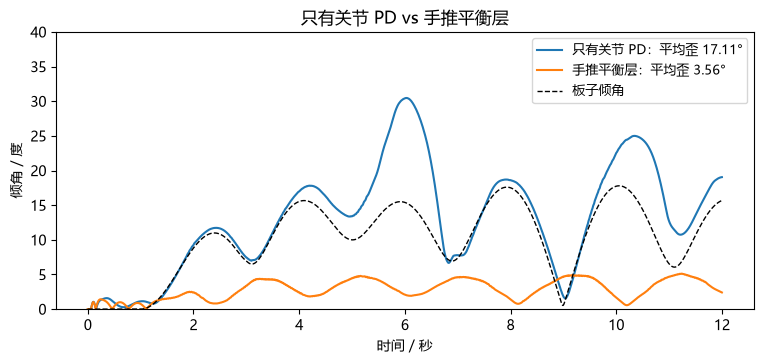

In [4]:
show({'只有关节 PD': Case(mode='pd'), '手推平衡层': Case(mode='geom')}, '只有关节 PD vs 手推平衡层')

## 2. 学一个平衡层

同一个接口：输入（机身倾角、角速度、当前腿长差）→ 输出（新的腿长差），中间换成 4 个数 `w`。
`train` 从 `w = 0` 开始，每轮随机挑方向，往正、往反各试一次，哪边歪得少就往哪边走。它不知道几何，只看回报。

和视频一样训练 40 轮（随机种子固定，结果和视频完全一样），大约 6 分钟，耐心等一下。

第  0 轮  w = [-0.25 -0.07  0.29  0.56]  验证回报     -20.0


第  1 轮  w = [-0.27 -0.94  0.88  0.71]  验证回报      -2.4


第  2 轮  w = [-0.52 -1.53  0.8   1.44]  验证回报      -0.7


第  3 轮  w = [-1.14 -1.74  0.61  1.49]  验证回报      -0.6


第  4 轮  w = [-1.32 -1.62  1.14  1.9 ]  验证回报      -0.4


...

第 35 轮  w = [-7.74 -1.15  8.05  1.59]  验证回报      -0.1


第 36 轮  w = [-7.77 -1.58  8.55  1.42]  验证回报      -0.1


第 37 轮  w = [-8.86 -1.39  8.6   1.87]  验证回报      -0.1


第 38 轮  w = [-8.98 -1.51  8.03  1.51]  验证回报      -0.1


第 39 轮  w = [-9.18 -1.75  8.79  1.58]  验证回报      -0.1


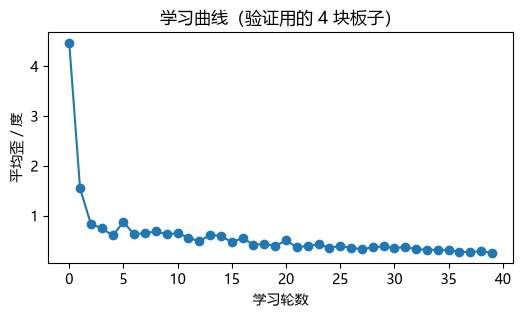

手推平衡层        平均歪    3.56°   最大    5.12°   趴下/翻了：False


学出来的         平均歪    0.38°   最大    0.79°   趴下/翻了：False


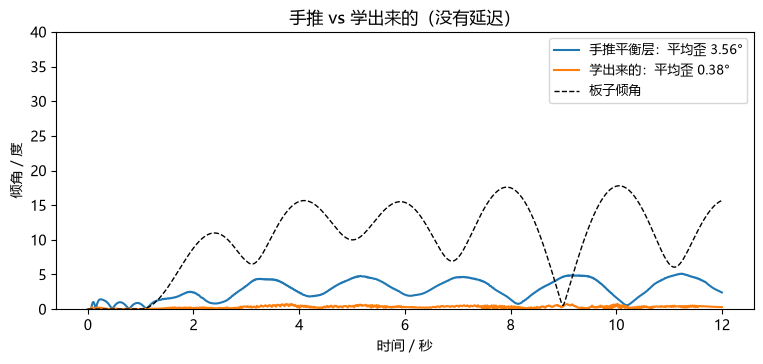

In [5]:
w, hist = train(iters=40, m=m)
plt.figure(figsize=(6, 3)); plt.plot([np.sqrt(-h[2]) for h in hist], 'o-')
plt.xlabel('学习轮数'); plt.ylabel('平均歪 / 度'); plt.title('学习曲线（验证用的 4 块板子）'); plt.show()
show({'手推平衡层': Case(mode='geom'), '学出来的': Case(mode='learned', w=w)}, '手推 vs 学出来的（没有延迟）')

## 3. 加上 20 毫秒延迟

真机上，从测到身子歪到腿真的伸长，总要隔几毫秒到几十毫秒。`delay=1` 表示晚一拍（20 毫秒）才看到。

手推 + 20 ms   平均歪    3.58°   最大    5.21°   趴下/翻了：False


学出来的 + 20 ms 平均歪  179.03°   最大  180.00°   趴下/翻了：True


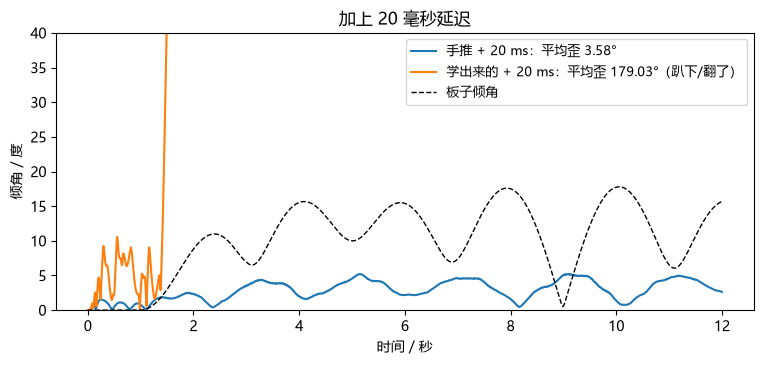

学到的横滚系数 -9.18 ；手推（α=0.1）相当于 -1.59


In [6]:
show({'手推 + 20 ms': Case(mode='geom', delay=1, imu_noise=np.radians(0.5), seed=1),
      '学出来的 + 20 ms': Case(mode='learned', w=w, delay=1, imu_noise=np.radians(0.5), seed=1)}, '加上 20 毫秒延迟')
print('学到的横滚系数', round(w[0], 2), '；手推（α=0.1）相当于', round(-0.1 * W / 0.02, 2))

## 4. 快与稳的取舍

手推平衡层每 20 毫秒只往目标走 α（默认 0.1）。α 越大改得越急：没有延迟时更准，有延迟时更容易改过头。

In [7]:
for a in [1.0, 0.3, 0.1]:
    row = []
    for dl in [0, 1, 2]:
        s = score(simulate(Case(mode='geom', alpha=a, delay=dl, imu_noise=np.radians(0.5) if dl else 0, seed=1), m))
        row.append('翻了' if s['趴下'] else f"{s['倾角RMS_deg']:.2f}°")
    print(f'α = {a:<4}  无延迟 {row[0]:>7}   20 ms {row[1]:>7}   40 ms {row[2]:>7}')

α = 1.0   无延迟   0.77°   20 ms      翻了   40 ms      翻了


α = 0.3   无延迟   1.24°   20 ms      翻了   40 ms      翻了


α = 0.1   无延迟   3.56°   20 ms   3.58°   40 ms   3.62°


## 作业

下面三格要你自己改、自己跑。

In [ ]:
# 作业 1：域随机化。训练时随机加 0–40 ms 延迟和 0–1° 噪声（randomize=True），
# 再测它在 40 ms、60 ms 延迟下的表现。然后想办法让它扛住 60 ms：代价是什么？
w_dr, _ = train(iters=15, randomize=True, m=m)
for dl in [2, 3]:
    s = score(simulate(Case(mode='learned', w=w_dr, delay=dl, imu_noise=np.radians(1), seed=1), m))
    print(dl * 20, 'ms：平均歪', round(s['倾角RMS_deg'], 2), '°  翻了：', s['趴下'])

In [ ]:
# 作业 2：把 α 从 0.05 拧到 1（多取几个值），延迟从 0 到 100 ms，自己画出完整的取舍表。


In [ ]:
# 作业 3：板子不是来回晃，而是在 2 秒时突然歪 10° 然后不动。
# 提示：仿照 board_angles(c, t) 写一个新的板子运动，比较手推和学出来的谁回正得快、谁更稳。
